# Tech Challenge Fase 1: triagem de risco de alteração glicêmica

Modelo de classificação binária com dados do BRFSS 2015 (CDC). Ele apoia um questionário
respondido pelo paciente na sala de espera. O resultado vai para o médico, que tem a palavra final.
O modelo é uma ferramenta de **triagem**, não de diagnóstico.

## 1. Problema e dados

- **Fonte:** BRFSS 2015, pesquisa telefônica autodeclarada do CDC (441.456 pessoas, 330 colunas).
- **Público do produto:** pacientes **sem** diagnóstico prévio de diabetes.
- **Alvo:** alteração glicêmica atual ou passada (diabetes, gestacional ou pré-diabetes).
- **Métrica principal:** recall da classe positiva. Um falso positivo custa uma glicemia de jejum;
  um falso negativo adia um diagnóstico.
- **Seleção de colunas:** das 330 originais ficaram 10 features. Saíram colunas administrativas,
  módulos opcionais (69–100% vazios), variáveis que só existem para quem já é diabético e variáveis
  que o paciente não saberia responder. Uma variável por tema, preferindo as calculadas pelo CDC.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
import seaborn as sb                    


## Visualização das colunas dos dados brutos 

Como na fase inicial ficou complicado visualizar todas as colunas porque o pandas restringe por padrão a quantidade de colunas, foi necessário a configuração para retirar essa restrição e mostrar todas as colunas disponíveis. Nesse contexto, o Clauce Code ajudou na segmentação e agrupamento das colunas para que seleção de quais colunas utilizar se tornasse mais fácil. 

In [2]:
pd.set_option("display.max_columns", None)

In [3]:
def encontrar_raiz(marcador: str = "requirements.txt") -> Path:
    """Sobe a partir do diretório atual até achar a pasta que contém o marcador."""
    atual = Path.cwd().resolve()
    for pasta in [atual, *atual.parents]:
        
        if (pasta / marcador).exists():
            return pasta
    raise FileNotFoundError(
        f"'{marcador}' não foi encontrado a partir de {atual}. "
        "Execute o notebook de dentro do projeto TC1."
    )


ROOT = encontrar_raiz()
XPT = ROOT / "dataset" / "raw" / "LLCP2015.XPT"
RECORTE = ROOT / "dataset" / "processed" / "brfss2015_recorte.parquet"
FIGURAS = ROOT / "reports" / "figures"

In [4]:
ALVO = "DIABETE3"  # 1 = sim, 2 = só na gravidez, 3 = não, 4 = pré-diabetes, 7 = não sabe, 9 = recusou

FEATURES = [
    "_AGEG5YR",  # faixas de 5 anos: 1 = 18–24 ... 13 = 80+, 14 = ausente
    "SEX",       # 1 = masculino, 2 = feminino
    "_BMI5",     # IMC com 2 casas decimais implícitas (2534 = 25,34); vazio = ausente
    "_SMOKER3",  # 1 = todo dia, 2 = alguns dias, 3 = ex-fumante, 4 = nunca fumou, 9 = ausente
    "EXERANY2",  # 1 = sim, 2 = não, 7 = não sabe, 9 = recusou (invertido em relação ao _RFDRHV5)
    "_RFDRHV5",  # bebedor pesado: 1 = não, 2 = sim, 9 = ausente
    "_RFCHOL",   # colesterol alto: 1 = não, 2 = sim, 9 = ausente, vazio = não mediu
    "_RFHYPE5",  # pressão alta: 1 = não, 2 = sim, 9 = ausente
    "GENHLTH",   # 1 = excelente ... 5 = ruim, 7 = não sabe, 9 = recusou
    "DIFFWALK",  # dificuldade para andar: 1 = sim, 2 = não, 7 = não sabe, 9 = recusou
]

## 2. Carga e primeira exploração

O XPT bruto tem 1,1 GB e fica fora do Git. Ele só é lido se o recorte ainda não existir.
O recorte tem 2 MB e fica versionado, então o notebook roda sem baixar nada.

In [5]:
if not RECORTE.exists():
    bruto = pd.read_sas(XPT, format="xport", encoding="latin-1")
    bruto[[ALVO, *FEATURES]].to_parquet(RECORTE)
    del bruto

df = pd.read_parquet(RECORTE)
df.shape

(441456, 11)

In [6]:
df.head()

,DIABETE3,_AGEG5YR,SEX,_BMI5,_SMOKER3,EXERANY2,_RFDRHV5,_RFCHOL,_RFHYPE5,GENHLTH,DIFFWALK
0,3.0,9.0,2.0,4018.0,3.0,2.0,1.0,2.0,2.0,5.0,1.0
1,3.0,7.0,2.0,2509.0,1.0,1.0,1.0,1.0,1.0,3.0,2.0
2,3.0,11.0,2.0,2204.0,9.0,NaN,9.0,2.0,1.0,4.0,NaN
3,3.0,9.0,2.0,2819.0,4.0,2.0,1.0,2.0,2.0,5.0,1.0
4,3.0,9.0,2.0,2437.0,4.0,2.0,1.0,1.0,1.0,5.0,2.0


### Uma primeira análise dos valores nulos

Os dados ainda contém valores que serão eliminados posteriormente.

In [7]:
pd.DataFrame({
    "qtd_nulos": df.isnull().sum(),
    "pct_nulos": (df.isnull().mean() * 100).round(2),
})

,qtd_nulos,pct_nulos
DIABETE3,7,0.00
_AGEG5YR,0,0.00
SEX,0,0.00
_BMI5,36398,8.24
_SMOKER3,0,0.00
EXERANY2,35444,8.03
_RFDRHV5,0,0.00
_RFCHOL,59154,13.40
_RFHYPE5,0,0.00
GENHLTH,2,0.00


In [8]:
df[ALVO].value_counts(dropna=False)

DIABETE3
3.0    372104
1.0     57256
4.0      7690
2.0      3608
7.0       598
9.0       193
NaN         7
Name: count, dtype: int64

## Informações do dataset

Outra visão para observar os valores nulos da base de dados. A mesma constatação da linha 8.

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 441456 entries, 0 to 441455
Data columns (total 11 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   DIABETE3  441449 non-null  float64
 1   _AGEG5YR  441456 non-null  float64
 2   SEX       441456 non-null  float64
 3   _BMI5     405058 non-null  float64
 4   _SMOKER3  441456 non-null  float64
 5   EXERANY2  406012 non-null  float64
 6   _RFDRHV5  441456 non-null  float64
 7   _RFCHOL   382302 non-null  float64
 8   _RFHYPE5  441456 non-null  float64
 9   GENHLTH   441454 non-null  float64
 10  DIFFWALK  429122 non-null  float64
dtypes: float64(11)
memory usage: 37.0 MB


## 3. Limpeza

Vamos realizar a limpeza da nossa base de dados. 

| Coluna | Regra |
|---|---|
| `DIABETE3` | Manter 1, 2, 3 e 4. Criar `alvo`: 1 se o código for 1, 2 ou 4; 0 se for 3 |
| `_AGEG5YR` | 14 vira NaN |
| `_BMI5` | Dividir por 100 |
| `_SMOKER3`, `_RFDRHV5`, `_RFHYPE5` | 9 vira NaN |
| `EXERANY2`, `GENHLTH`, `DIFFWALK` | 7 e 9 viram NaN |
| `_RFCHOL` | Vazio vira 3 ("não mediu") **antes**; depois, 9 vira NaN |

Ao final, confira com `dados.isnull().mean()` e `dados["alvo"].mean()`: a prevalência deve dar cerca de 15,6%.

### DIABETE3
- Limpeza dos nulo
- Transformação de DIABETE3 (1,2,3,4) para ALVO (1,0) onde 1,2 e4 viram 1(true) e 3 vira 0 (falso)
- Remove a coluna DIABETE3

In [10]:
dados = df[df[ALVO].isin([1, 2, 3, 4])].copy()
dados["alvo"] = dados[ALVO].isin([1, 2, 4]).astype(int)  # True/False vira 1/0
dados = dados.drop(columns=ALVO)
dados.info()

<class 'pandas.DataFrame'>
Index: 440658 entries, 0 to 441455
Data columns (total 11 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   _AGEG5YR  440658 non-null  float64
 1   SEX       440658 non-null  float64
 2   _BMI5     404467 non-null  float64
 3   _SMOKER3  440658 non-null  float64
 4   EXERANY2  405330 non-null  float64
 5   _RFDRHV5  440658 non-null  float64
 6   _RFCHOL   381712 non-null  float64
 7   _RFHYPE5  440658 non-null  float64
 8   GENHLTH   440656 non-null  float64
 9   DIFFWALK  428369 non-null  float64
 10  alvo      440658 non-null  int64  
dtypes: float64(10), int64(1)
memory usage: 40.3 MB


### _AGEG5YR

14 vira Nulo, porque? Essa coluna indica a faixa etária, e o número 14 são pessoas que não responderam, se recusaram a responder ou sem

### _BMI5

Nas notas do dataset é informado que esta coluna foi acrescida duas casas decimais, portanto, vamos dividir por 100. A informação de nulos não se altera neste caso.

In [11]:
dados["_BMI5"] = dados["_BMI5"] / 100
dados.info()

<class 'pandas.DataFrame'>
Index: 440658 entries, 0 to 441455
Data columns (total 11 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   _AGEG5YR  440658 non-null  float64
 1   SEX       440658 non-null  float64
 2   _BMI5     404467 non-null  float64
 3   _SMOKER3  440658 non-null  float64
 4   EXERANY2  405330 non-null  float64
 5   _RFDRHV5  440658 non-null  float64
 6   _RFCHOL   381712 non-null  float64
 7   _RFHYPE5  440658 non-null  float64
 8   GENHLTH   440656 non-null  float64
 9   DIFFWALK  428369 non-null  float64
 10  alvo      440658 non-null  int64  
dtypes: float64(10), int64(1)
memory usage: 40.3 MB


### _SMOKER3 _RFDRHV5 _RFHYPE5

9 viram nulos, porque? 9 significa não sabe, se recusou a informar ou não preenchido. O total de nulos aumenta aqui para estas colunas.

### `EXERANY2`, `GENHLTH`, `DIFFWALK`

7 e 9 viram nulos. 

### _RFCHOL

Nulos viram 3. Categoria criada 3: sem medição confirmada.

In [12]:
dados["_RFCHOL"] = dados["_RFCHOL"].fillna(3)                # 1º: vazio = "nunca mediu"

In [13]:
CODIGOS_AUSENTES = {
    "_AGEG5YR": [14],
    "_SMOKER3": [9],
    "_RFDRHV5": [9],
    "_RFHYPE5": [9],
    "_RFCHOL": [9],
    "EXERANY2": [7, 9],
    "GENHLTH": [7, 9],
    "DIFFWALK": [7, 9],
}

for coluna, codigos in CODIGOS_AUSENTES.items():
    dados[coluna] = dados[coluna].replace(codigos, np.nan)

In [14]:
dados.isnull().mean()

_AGEG5YR    0.011878
SEX         0.000000
_BMI5       0.082129
_SMOKER3    0.040594
EXERANY2    0.085894
_RFDRHV5    0.058084
_RFCHOL     0.007888
_RFHYPE5    0.002855
GENHLTH     0.002789
DIFFWALK    0.032912
alvo        0.000000
dtype: float64

In [15]:
dados["alvo"].mean()

np.float64(0.15557189475738556)

In [16]:
dados["_BMI5"].describe()

count    404467.000000
mean         28.040245
std           6.653276
min          12.020000
25%          23.730000
50%          26.950000
75%          30.900000
max          99.950000
Name: _BMI5, dtype: float64

## 4. Análise exploratória

**Sua vez:** `dados.describe()`, histogramas, proporção do alvo e heatmap de correlação (Aula 4),
com um comentário sobre cada resultado.

In [17]:
dados.describe()

,_AGEG5YR,SEX,_BMI5,_SMOKER3,EXERANY2,_RFDRHV5,_RFCHOL,_RFHYPE5,GENHLTH,DIFFWALK,alvo
count,435424.000000,440658.000000,404467.000000,422770.000000,402808.000000,415063.000000,437182.000000,439400.000000,439429.000000,426155.000000,440658.000000
mean,7.727546,1.576706,28.040245,3.317686,1.266139,1.053110,1.634932,1.404697,2.563308,1.825334,0.155572
std,3.448355,0.494082,6.653276,0.958575,0.441938,0.224253,0.708137,0.490834,1.083727,0.379682,0.362449
min,1.000000,1.000000,12.020000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,5.000000,1.000000,23.730000,3.000000,1.000000,1.000000,1.000000,1.000000,2.000000,2.000000,0.000000
50%,8.000000,2.000000,26.950000,4.000000,1.000000,1.000000,2.000000,1.000000,2.000000,2.000000,0.000000
75%,10.000000,2.000000,30.900000,4.000000,2.000000,1.000000,2.000000,2.000000,3.000000,2.000000,0.000000
max,13.000000,2.000000,99.950000,4.000000,2.000000,2.000000,3.000000,2.000000,5.000000,2.000000,1.000000


<Axes: xlabel='_BMI5', ylabel='Percent'>

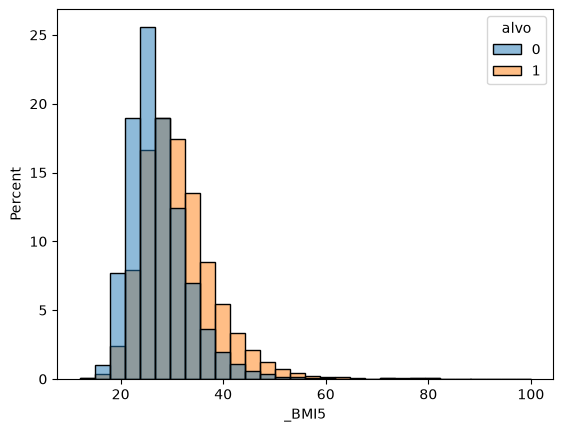

In [18]:
sb.histplot(data=dados, x="_BMI5", hue="alvo", stat="percent", common_norm=False, bins=30)

## Proporção do alvo

Aqui conseguimos ver que entre os dados analisados, existem 84 % sem alteração glicemica e em torno de 16 % com alteração glicemica.

In [19]:
pd.DataFrame({
    "qtd": dados["alvo"].value_counts(),
    "pct": (dados["alvo"].value_counts(normalize=True) * 100).round(2),
})


,qtd,pct
alvo,,
0,372104,84.44
1,68554,15.56


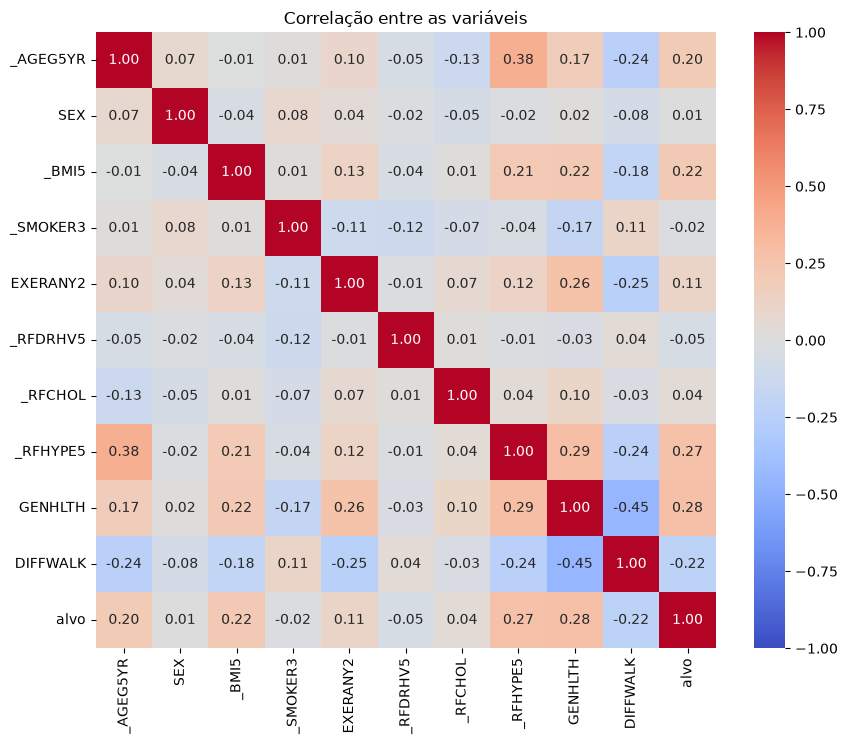

In [20]:
correlacao = dados.corr()

plt.figure(figsize=(10, 8))
sb.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlação entre as variáveis")
plt.savefig(FIGURAS / "correlacao.png", dpi=150, bbox_inches="tight")
plt.show()


### Descoberta: os hábitos e o momento do diagnóstico

O BRFSS retrata o hábito **atual**, e o diagnóstico pode ter acontecido anos antes. As análises abaixo
comparam a prevalência do alvo dentro de cada faixa etária, para separar o efeito da idade.

In [21]:
FAIXAS = ["18–24", "25–29", "30–34", "35–39", "40–44", "45–49", "50–54",
          "55–59", "60–64", "65–69", "70–74", "75–79", "80+"]  # códigos 1 a 13 do _AGEG5YR


def prevalencia_por_idade(df, coluna, validos, rotulos):
    """Prevalência do alvo por faixa etária e pelos grupos de `coluna`.

    validos: códigos da coluna que entram (ex.: [1, 2])
    rotulos: nomes dos grupos, NA ORDEM dos códigos (ex.: ["Sim", "Não"])
    """
    d = df[[ALVO, "_AGEG5YR", coluna]].copy()
    d = d[d[ALVO].isin([1, 2, 3, 4])]
    d["alvo"] = d[ALVO].isin([1, 2, 4]).astype(int)
    d = d[d[coluna].isin(validos)]
    d = d[d["_AGEG5YR"].isin(range(1, 14))]

    tab = d.groupby(["_AGEG5YR", coluna])["alvo"].mean().unstack()
    tab.columns = rotulos
    return tab


def plot_prevalencia_por_idade(tab, titulo, arquivo):
    """Plota a tabela de `prevalencia_por_idade` e salva a figura em reports/figures."""
    ax = tab.plot(marker="o", figsize=(9, 5))
    ax.set_xticks(range(1, 14))  # o índice da tabela são os próprios códigos 1 a 13
    ax.set_xticklabels(FAIXAS, rotation=45)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlabel("Faixa etária")
    ax.set_ylabel("Prevalência de alteração glicêmica")
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
    plt.savefig(FIGURAS / arquivo, dpi=150, bbox_inches="tight")
    plt.show()

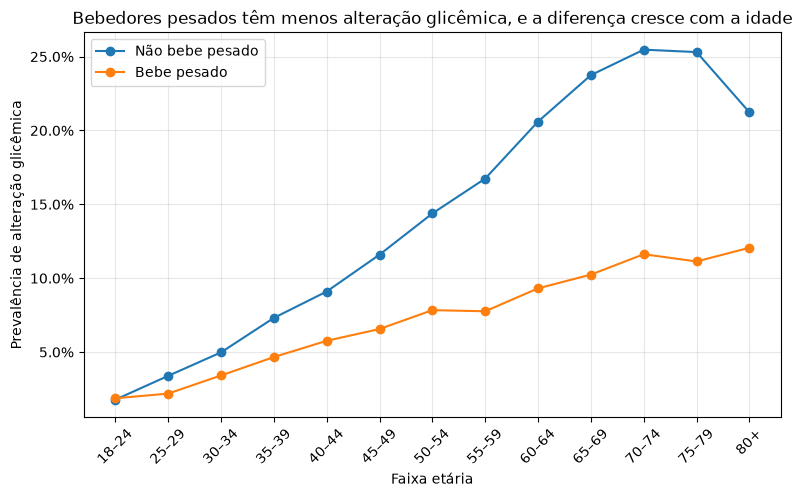

,Não bebe pesado,Bebe pesado
_AGEG5YR,,
1.0,0.018,0.019
2.0,0.034,0.022
3.0,0.050,0.034
4.0,0.073,0.047
5.0,0.091,0.058
6.0,0.116,0.066
7.0,0.144,0.078
8.0,0.167,0.078
9.0,0.206,0.093


In [22]:
tab_alcool = prevalencia_por_idade(df, "_RFDRHV5", [1, 2], ["Não bebe pesado", "Bebe pesado"])
plot_prevalencia_por_idade(
    tab_alcool,
    "Bebedores pesados têm menos alteração glicêmica, e a diferença cresce com a idade",
    "alcool_vs_idade.png",
)
tab_alcool.round(3)

**Álcool.** Ao contrário do esperado, bebedores pesados têm menos da metade da prevalência (7,4% contra
16,2%). A diferença persiste dentro das faixas etárias, exceto aos 18–24 anos, quando os grupos são
iguais (1,8% e 1,9%), e cresce com a idade. O padrão é coerente com a **causalidade reversa**: quem
recebe o diagnóstico tende a mudar de hábito. É uma hipótese, porque o dado é uma foto de um único
momento e não permite comprová-la.

A idade está muito mais associada ao alvo (1,8% → 25%) do que o álcool (até ~2,3× dentro da mesma faixa,
e só 5% da população). Hipótese a verificar com o SHAP na seção 9.

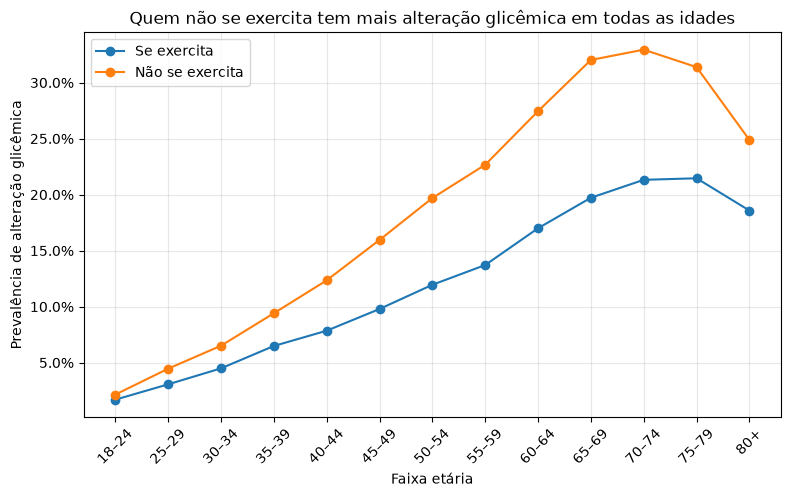

,Se exercita,Não se exercita
_AGEG5YR,,
1.0,0.017,0.021
2.0,0.031,0.045
3.0,0.045,0.065
4.0,0.065,0.094
5.0,0.079,0.123
6.0,0.098,0.160
7.0,0.120,0.197
8.0,0.137,0.227
9.0,0.170,0.274


In [23]:
tab_exercicio = prevalencia_por_idade(df, "EXERANY2", [1, 2], ["Se exercita", "Não se exercita"])
plot_prevalencia_por_idade(
    tab_exercicio,
    "Quem não se exercita tem mais alteração glicêmica em todas as idades",
    "exercicio_vs_idade.png",
)
tab_exercicio.round(3)

**Exercício.** Aqui o resultado confirma o esperado, em todas as faixas. No início da idade adulta a
diferença é pequena, mas já existe (1,7% e 2,1%), e aumenta à medida que a idade avança. Diferente do
álcool, ela aparece antes dos diagnósticos se acumularem.

**Consequência para o modelo.** O treino retrata muitos diabéticos **depois** do diagnóstico, mas o
produto atende quem **ainda não** foi diagnosticado. Isso é uma limitação documentada: o efeito das
variáveis de hábito deve ser lido como associação, nunca como causa.

## 5. Separação treino, validação e teste

Como vamos precisar de 3 conjuntos de dados, treino, teste e validação, vamos fazer duas separações ficando com 60% para treino, 20% para teste e 20% para validação.

In [24]:
from sklearn.model_selection import train_test_split

#Separando os dados
x = dados.drop(columns=['alvo'])
y = dados['alvo'] 

X_treino_tmp, X_teste, y_treino_tmp, y_teste = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

X_treino, X_val, y_treino, y_val = train_test_split(
    X_treino_tmp, y_treino_tmp, test_size=0.25, random_state=42, stratify=y_treino_tmp
)


## 6. Pipeline de pré-processamento

Somente a _BMI5 foi considerada nomerica e as outras colunas foram consideradas categoricas inclusive a idade.

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUMERICAS = ["_BMI5"]
CATEGORICAS = [c for c in FEATURES if c not in NUMERICAS]

pipeline_num = Pipeline([
    ("imputador", SimpleImputer(strategy="mean")),
    ("escala", StandardScaler()),
])

pipeline_cat = Pipeline([
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessador = ColumnTransformer([
    ("num", pipeline_num, NUMERICAS),
    ("cat", pipeline_cat, CATEGORICAS),
])


## 7. Modelos

**Sua vez:** um baseline (`DummyClassifier`) e dois modelos com `class_weight="balanced"`, por exemplo
Árvore de Decisão (Aula 4), Random Forest (Aula 4) ou Regressão Logística. Compare na **validação**.

In [36]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, recall_score, roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

In [37]:
modelos = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "Árvore de Decisão": DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20,
                                        class_weight="balanced", n_jobs=-1, random_state=42),
}

resultados = {}
ajustados = {}

for nome, classificador in modelos.items():
    pipe = Pipeline([
        ("preprocessador", preprocessador),
        ("classificador", classificador),
    ])
    pipe.fit(X_treino, y_treino)
    ajustados[nome] = pipe

    # calcule aqui recall, F1 e AUC na validação e guarde em resultados[nome]

    pred_val = pipe.predict(X_val)
    prob_val = pipe.predict_proba(X_val)[:, 1]

    resultados[nome] = {
        "recall": recall_score(y_val, pred_val),
        "f1": f1_score(y_val, pred_val),
        "auc": roc_auc_score(y_val, prob_val),
    }
    
pd.DataFrame(resultados).T


,recall,f1,auc
Baseline,0.000000,0.000000,0.500000
Regressão Logística,0.756983,0.453866,0.805139
Árvore de Decisão,0.739771,0.447666,0.795279
Random Forest,0.759099,0.454905,0.806814


## 8. Limiar e avaliação final

**Sua vez:** escolha o limiar de decisão na validação, olhando recall e precisão. Depois avalie o modelo
escolhido no **teste, uma única vez**, com `classification_report` e matriz de confusão (Aula 5).

In [38]:
from sklearn.metrics import precision_recall_curve

melhor = ajustados["Regressão Logística"]  # nome do modelo escolhido
RECALL_MINIMO = 0.80

prob_val = melhor.predict_proba(X_val)[:, 1]
precisoes, recalls, limiares = precision_recall_curve(y_val, prob_val)

limiar = limiares[np.argmax(recalls >= RECALL_MINIMO)]  # o limiar mais alto que mantém recall >= RECALL_MINIMO

## 9. Interpretação

**Sua vez:** feature importance e SHAP (com uma amostra). A idade aparece acima do álcool? O álcool
aparece reduzindo o risco? Confira também as métricas por sexo: o código 2 do alvo só existe em mulheres.

In [ ]:
# Escreva aqui a interpretação


## 10. Discussão crítica

Não acredito que o modelo possa ser usado na pratica pois ainda não tenho a confiaça necessaria preciso estudar mais.
**Sua vez:** o modelo pode ser usado na prática? Como? Pontos a cobrir: o médico tem a palavra final,
o alvo é autodeclarado, a população do BRFSS difere da de uma sala de espera, há causalidade reversa
nos hábitos e o alvo é mais amplo que "tem diabetes".